# 05. Temporal Analysis
Summarise by calendar month and year. Monthly flow sums represent observed reporting values and may be incomplete where reporting coverage varies.

In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /Users/shrii/DS_Projects/System Capacity & Care Load Analytics for Unaccompanied Children


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

FEATURES_PATH = PROJECT_ROOT / "data" / "processed" / "uac_features.csv"

features = pd.read_csv(FEATURES_PATH, parse_dates=["date"])

print("Dataset shape:", features.shape)
print("Date range:", features["date"].min(), "to", features["date"].max())

display(features.head())

Dataset shape: (720, 27)
Date range: 2023-01-12 00:00:00 to 2025-12-21 00:00:00


,date,cbp_intake,cbp_custody,transfers_to_hhs,hhs_care,hhs_discharges,total_system_load,hhs_net_flow,system_net_flow,hhs_discharge_offset_ratio,...,hhs_care_rolling_mean_14obs,hhs_care_rolling_std_14obs,system_load_rolling_mean_14obs,system_net_flow_sum_14obs,care_load_volatility_index,high_system_load_flag,sustained_positive_net_flow_flag,reporting_gap_days,year_month,year
0,2023-01-12,33.0,53.0,34.0,6566,436.0,6619.0,-402.0,-403.0,12.823529,...,NaN,NaN,NaN,NaN,NaN,False,False,NaN,2023-01,2023
1,2023-01-22,32.0,49.0,39.0,7122,227.0,7171.0,-188.0,-195.0,5.820513,...,NaN,NaN,NaN,NaN,NaN,False,False,10.0,2023-01,2023
2,2023-01-23,32.0,50.0,39.0,7280,181.0,7330.0,-142.0,-149.0,4.641026,...,NaN,NaN,NaN,NaN,NaN,False,False,1.0,2023-01,2023
3,2023-01-24,47.0,42.0,47.0,7433,175.0,7475.0,-128.0,-128.0,3.723404,...,NaN,NaN,NaN,NaN,NaN,False,False,1.0,2023-01,2023
4,2023-01-25,20.0,22.0,41.0,7538,180.0,7560.0,-139.0,-160.0,4.390244,...,NaN,NaN,NaN,NaN,NaN,False,False,1.0,2023-01,2023


In [4]:
from src.analysis import monthly_summary, period_summary
monthly = monthly_summary(features)
display(monthly.head())

,date,cbp_intake,cbp_custody_mean,transfers_to_hhs,hhs_care_mean,hhs_discharges,total_system_load_mean,system_net_flow,reporting_observations
0,2023-01-01,247.0,43.875000,276.0,7369.625000,1856.0,7413.500000,-1609.0,8
1,2023-02-01,1886.0,171.315789,2637.0,7795.789474,5183.0,7967.105263,-3297.0,19
2,2023-03-01,2479.0,245.105263,3399.0,7945.368421,5375.0,8190.473684,-2896.0,19
3,2023-04-01,3129.0,250.190476,3967.0,7842.666667,5668.0,8092.857143,-2539.0,21
4,2023-05-01,2746.0,216.954545,3622.0,8187.136364,6256.0,8404.090909,-3510.0,22


In [5]:
yearly = period_summary(features, 'year')
display(yearly)

,year,observations,mean_system_load,mean_hhs_care,total_intake_observed,total_discharges_observed,mean_hhs_net_flow
0,2023,230,8846.543478,8646.073913,27056.0,66244.0,-130.956522
1,2024,251,7319.864542,7042.960159,37166.0,51689.0,3.438247
2,2025,239,2575.744770,2542.836820,3115.0,6920.0,-12.364017


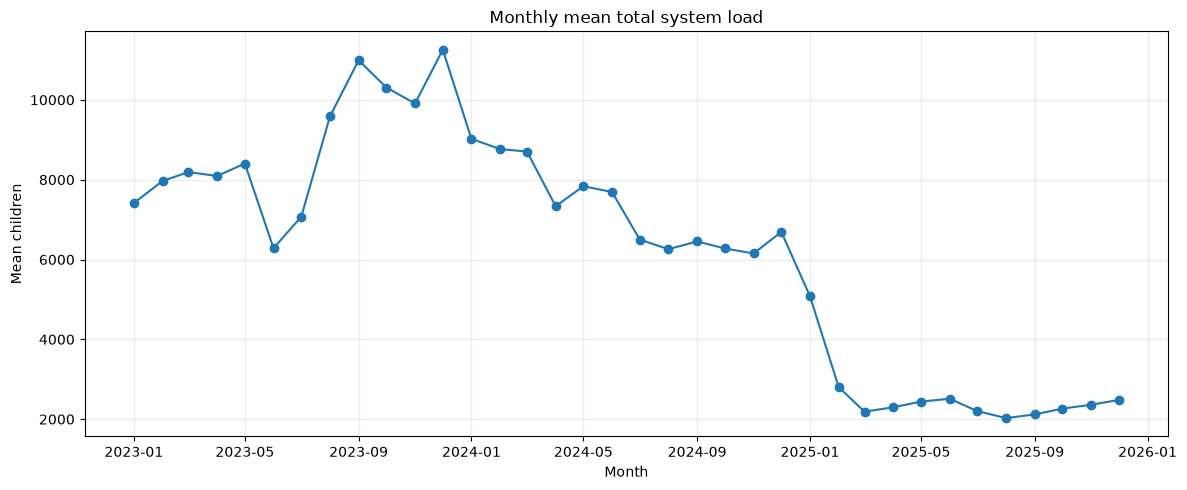

In [6]:
fig, ax = plt.subplots(figsize=(12,5))
ax.plot(monthly.date, monthly.total_system_load_mean, marker='o')
ax.set(title='Monthly mean total system load', xlabel='Month', ylabel='Mean children')
ax.grid(alpha=.25)
plt.tight_layout()